In [4]:
import pandas as pd
import numpy as np

# 1. Load train and test data

train_path = r"D:\上海大学课程资料\南洋理工课程资料\数据挖掘\dataset\dataset\train.csv"
test_path = r"D:\上海大学课程资料\南洋理工课程资料\数据挖掘\dataset\dataset\test.csv"

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("=" * 70)
print("DATA LOADING")
print("=" * 70)

print(f"Train shape: {train.shape}")
print(f"Test shape : {test.shape}")

print("\nTrain columns:")
print(train.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())


# 2. Basic information

print("\n" + "=" * 70)
print("BASIC DATA INFORMATION")
print("=" * 70)

print("\nTrain data types:")
print(train.dtypes)

print("\nTest data types:")
print(test.dtypes)

print("\nTrain info:")
train.info()


# 3. Check column consistency

print("\n" + "=" * 70)
print("COLUMN CONSISTENCY")
print("=" * 70)

train_columns = set(train.columns)
test_columns = set(test.columns)

print("Columns only in train:")
print(train_columns - test_columns)

print("\nColumns only in test:")
print(test_columns - train_columns)

print("\nSame columns:", train_columns == test_columns)


# 4. Check missing values

print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

train_missing = train.isnull().sum()
test_missing = test.isnull().sum()

missing_summary = pd.DataFrame({
    "Train_Missing": train_missing,
    "Train_Missing_%": train_missing / len(train) * 100,
    "Test_Missing": test_missing,
    "Test_Missing_%": test_missing / len(test) * 100
})

print(missing_summary)

print("\nTotal missing values in train:", train.isnull().sum().sum())
print("Total missing values in test :", test.isnull().sum().sum())


# 5. Check "Unknown" values

print("\n" + "=" * 70)
print("UNKNOWN VALUES")
print("=" * 70)

categorical_columns = train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_columns:
    train_unknown = (train[col] == "Unknown").sum()
    test_unknown = (test[col] == "Unknown").sum()

    if train_unknown > 0 or test_unknown > 0:
        print(
            f"{col}: "
            f"Train = {train_unknown} ({train_unknown/len(train)*100:.2f}%), "
            f"Test = {test_unknown} ({test_unknown/len(test)*100:.2f}%)"
        )



# 6. Check duplicated rows

print("\n" + "=" * 70)
print("DUPLICATE ROWS")
print("=" * 70)

train_duplicates = train.duplicated().sum()
test_duplicates = test.duplicated().sum()

print(f"Duplicated rows in train: {train_duplicates}")
print(f"Duplicated rows in test : {test_duplicates}")


# 7. Check target variable distribution

print("\n" + "=" * 70)
print("TARGET CLASS DISTRIBUTION")
print("=" * 70)

target = "label"

print("\nTrain label counts:")
print(train[target].value_counts())

print("\nTrain label proportions:")
print(
    train[target]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTest label counts:")
print(test[target].value_counts())

print("\nTest label proportions:")
print(
    test[target]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# 8. Numerical feature summary

print("\n" + "=" * 70)
print("NUMERICAL FEATURES - DESCRIPTIVE STATISTICS")
print("=" * 70)

numeric_columns = train.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNumerical columns:")
print(numeric_columns)

print("\nDescriptive statistics:")
print(
    train[numeric_columns]
    .describe()
    .T
)



# 9. Categorical feature summary

print("\n" + "=" * 70)
print("CATEGORICAL FEATURES")
print("=" * 70)

print("\nCategorical columns:")
print(categorical_columns)

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print("Number of unique values:", train[col].nunique())
    print(train[col].value_counts().head(15))



# 10. Outlier detection using IQR

print("\n" + "=" * 70)
print("OUTLIER DETECTION USING IQR")
print("=" * 70)

outlier_summary = []

for col in numeric_columns:

    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = train[
        (train[col] < lower_bound) |
        (train[col] > upper_bound)
    ]

    outlier_count = len(outliers)

    outlier_summary.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_%": outlier_count / len(train) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

print(
    outlier_summary.sort_values(
        "Outlier_Count",
        ascending=False
    ).to_string(index=False)
)



# 11. Check whether test contains categories not seen in train

print("\n" + "=" * 70)
print("UNSEEN CATEGORIES IN TEST")
print("=" * 70)

for col in categorical_columns:

    train_categories = set(train[col].dropna().unique())
    test_categories = set(test[col].dropna().unique())

    unseen = test_categories - train_categories

    if unseen:
        print(f"{col}: {unseen}")
    else:
        print(f"{col}: No unseen categories")



# 12. Check train-test duplicate records

print("\n" + "=" * 70)
print("TRAIN-TEST OVERLAP CHECK")
print("=" * 70)

# Convert rows to tuples so we can compare complete records
train_rows = set(map(tuple, train.astype(str).values))
test_rows = set(map(tuple, test.astype(str).values))

overlap = train_rows.intersection(test_rows)

print("Exact duplicate rows appearing in both train and test:",
      len(overlap))


# 13. Check possible ID columns

print("\n" + "=" * 70)
print("POSSIBLE ID COLUMNS")
print("=" * 70)

for col in train.columns:

    unique_ratio = train[col].nunique() / len(train)

    if unique_ratio > 0.95:
        print(
            f"{col}: {train[col].nunique()} unique values "
            f"({unique_ratio*100:.2f}%)"
        )


# 14. Check composite_rank relationship with other numerical features

print("\n" + "=" * 70)
print("CORRELATION ANALYSIS")
print("=" * 70)

if "composite_rank" in train.columns:

    correlation = (
        train[numeric_columns]
        .corr()["composite_rank"]
        .sort_values(ascending=False)
    )

    print("\nCorrelation with composite_rank:")
    print(correlation)


# 15. Overall data exploration summary

print("\n" + "=" * 70)
print("OVERALL SUMMARY")
print("=" * 70)

print(f"Train samples       : {len(train):,}")
print(f"Test samples        : {len(test):,}")
print(f"Total features      : {len(train.columns) - 1}")
print(f"Numerical features  : {len(numeric_columns)}")
print(f"Categorical features: {len(categorical_columns)}")
print(f"Train missing cells : {train.isnull().sum().sum():,}")
print(f"Test missing cells  : {test.isnull().sum().sum():,}")
print(f"Train duplicates    : {train_duplicates:,}")
print(f"Test duplicates     : {test_duplicates:,}")
print(f"Train/Test overlap  : {len(overlap):,}")

DATA LOADING
Train shape: (31112, 16)
Test shape : (13334, 16)

Train columns:
['geological_era', 'weather_pattern', 'region', 'aptitude_score', 'performance_score', 'stability_index', 'personal_interest', 'load_ratio', 'brew_preference', 'instrument', 'species', 'index_weight', 'mineral_type', 'activity_duration', 'composite_rank', 'label']

Test columns:
['geological_era', 'weather_pattern', 'region', 'aptitude_score', 'performance_score', 'stability_index', 'personal_interest', 'load_ratio', 'brew_preference', 'instrument', 'species', 'index_weight', 'mineral_type', 'activity_duration', 'composite_rank', 'label']

BASIC DATA INFORMATION

Train data types:
geological_era        object
weather_pattern       object
region                object
aptitude_score       float64
performance_score    float64
stability_index      float64
personal_interest     object
load_ratio           float64
brew_preference       object
instrument            object
species               object
index_weight  

mineral_type: No unseen categories
label: No unseen categories

TRAIN-TEST OVERLAP CHECK
Exact duplicate rows appearing in both train and test: 0

POSSIBLE ID COLUMNS

CORRELATION ANALYSIS

Correlation with composite_rank:
composite_rank       1.000000
performance_score    0.879907
stability_index      0.829886
aptitude_score       0.506460
activity_duration    0.128736
index_weight        -0.078539
load_ratio          -0.180251
Name: composite_rank, dtype: float64

OVERALL SUMMARY
Train samples       : 31,112
Test samples        : 13,334
Total features      : 15
Numerical features  : 7
Categorical features: 9
Train missing cells : 50
Test missing cells  : 21
Train duplicates    : 0
Test duplicates     : 0
Train/Test overlap  : 0


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

target = "label"

print("Missing target values before cleaning:")
print("Train:", train[target].isna().sum())
print("Test :", test[target].isna().sum())

train = train.dropna(subset=[target]).copy()
test = test.dropna(subset=[target]).copy()

print("\nShape after removing missing labels:")
print("Train:", train.shape)
print("Test :", test.shape)


X_train = train.drop(columns=[target])
y_train = train[target]

X_test = test.drop(columns=[target])
y_test = test[target]


numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)


X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("\nOriginal number of features:", X_train.shape[1])
print("Processed number of features:", X_train_processed.shape[1])

print("\nFirst 20 processed feature names:")
print(feature_names[:20])

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("\nMissing values after preprocessing:")
print(
    "Train:",
    X_train_processed.isna().sum().sum()
)

print(
    "Test :",
    X_test_processed.isna().sum().sum()
)

print("\nTarget distribution after cleaning:")

print("\nTrain:")
print(y_train.value_counts())
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTest:")
print(y_test.value_counts())
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\n" + "=" * 70)
print("PREPROCESSING SUMMARY")
print("=" * 70)

print(f"Original train rows : 31,112")
print(f"Cleaned train rows  : {len(X_train):,}")

print(f"Original test rows  : 13,334")
print(f"Cleaned test rows   : {len(X_test):,}")

print(f"\nOriginal features   : {X_train.shape[1]}")
print(f"Processed features  : {X_train_processed.shape[1]}")

print("\nNumerical processing:")
print("- Missing values -> median")

print("\nCategorical processing:")
print("- Missing values -> most frequent category")
print("- One-hot encoding -> applied")

print("\nOther decisions:")
print("- 'Unknown' values retained")
print("- Outliers retained")
print("- No feature scaling")
print("- No class resampling")
print("- composite_rank retained for further analysis")

Missing target values before cleaning:
Train: 3
Test : 1

Shape after removing missing labels:
Train: (31109, 16)
Test : (13333, 16)

Numerical features:
['aptitude_score', 'performance_score', 'stability_index', 'load_ratio', 'index_weight', 'activity_duration', 'composite_rank']

Categorical features:
['geological_era', 'weather_pattern', 'region', 'personal_interest', 'brew_preference', 'instrument', 'species', 'mineral_type']

Original number of features: 15
Processed number of features: 82

First 20 processed feature names:
['num__aptitude_score' 'num__performance_score' 'num__stability_index'
 'num__load_ratio' 'num__index_weight' 'num__activity_duration'
 'num__composite_rank' 'cat__geological_era_Cambrian'
 'cat__geological_era_Devonian' 'cat__geological_era_Jurassic'
 'cat__geological_era_Permian' 'cat__geological_era_Triassic'
 'cat__weather_pattern_Blizzard' 'cat__weather_pattern_Drizzle'
 'cat__weather_pattern_Fog' 'cat__weather_pattern_Frost'
 'cat__weather_pattern_Heatwav

Decision Tree Hyperparameter Tuning
Fitting 5 folds for each of 18 candidates, totalling 90 fits


D:\anaconda\Lib\site-packages\sklearn\model_selection\_search.py:952: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(



Best Decision Tree parameters:
{'max_depth': 3, 'min_samples_split': 2}
Best CV F1-score:
nan

Random Forest Hyperparameter Tuning
Fitting 5 folds for each of 16 candidates, totalling 80 fits


D:\anaconda\Lib\site-packages\sklearn\model_selection\_search.py:952: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(



Best Random Forest parameters:
{'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 100}
Best CV F1-score:
nan

Final Test Set Performance
           Model  Accuracy  Precision  Recall  F1-score
0  Decision Tree    0.8204     0.7192  0.4003    0.5143
1  Random Forest    0.8256     0.7435  0.4062    0.5254


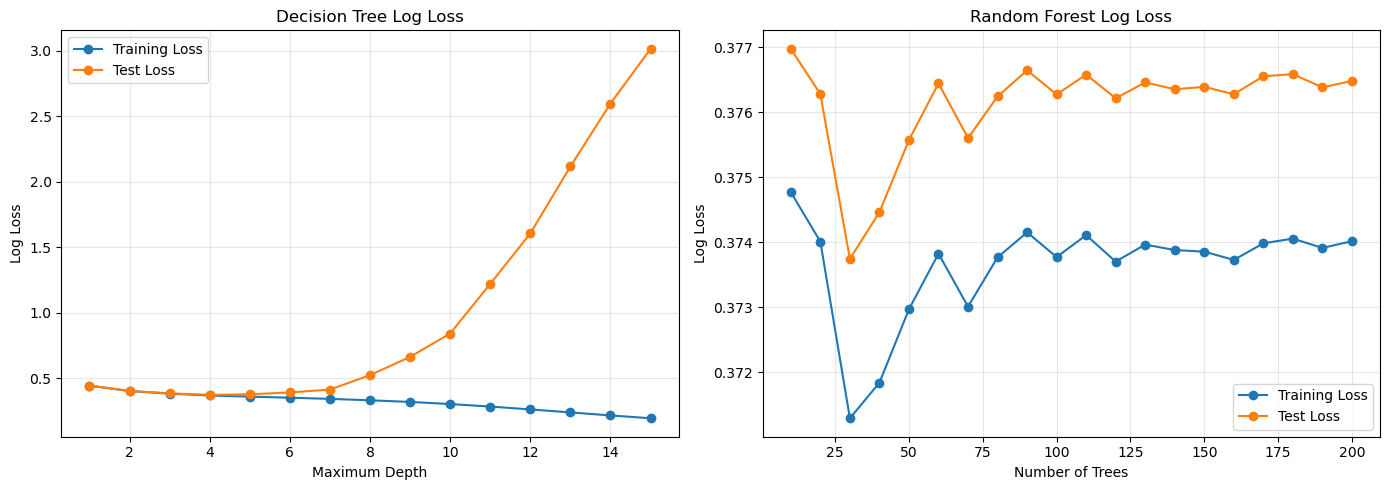

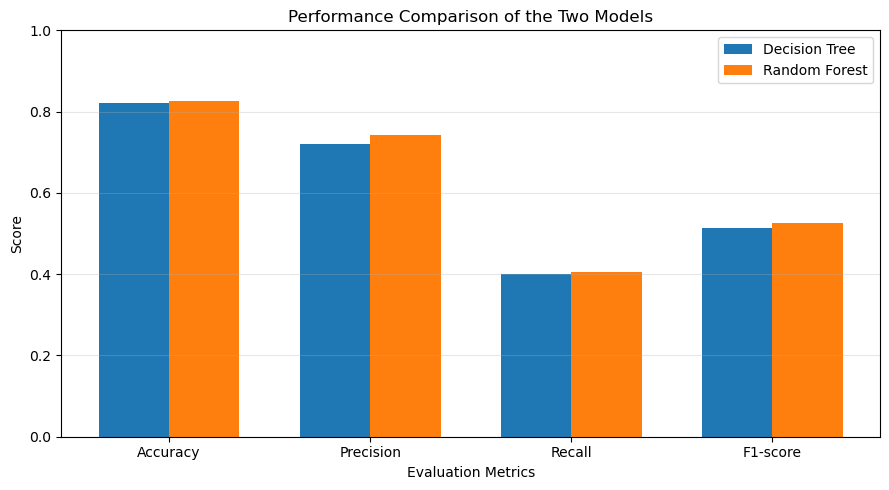


Best Model Based on Test F1-score
Random Forest with F1-score = 0.5254


In [6]:

import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)


# 2. Define models and hyperparameter grids

# Decision Tree
dt = DecisionTreeClassifier(
    random_state=42,
    criterion='gini'
)

dt_param_grid = {
    'max_depth': [3, 5, 7, 10, 15, None],
    'min_samples_split': [2, 5, 10]
}


# Random Forest
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5]
}



# 3. Hyperparameter tuning

print("=" * 70)
print("Decision Tree Hyperparameter Tuning")
print("=" * 70)

dt_grid = GridSearchCV(
    estimator=dt,
    param_grid=dt_param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

dt_grid.fit(X_train_processed, y_train)

print("\nBest Decision Tree parameters:")
print(dt_grid.best_params_)

print("Best CV F1-score:")
print(round(dt_grid.best_score_, 4))


print("\n" + "=" * 70)
print("Random Forest Hyperparameter Tuning")
print("=" * 70)

rf_grid = GridSearchCV(
    estimator=rf,
    param_grid=rf_param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train_processed, y_train)

print("\nBest Random Forest parameters:")
print(rf_grid.best_params_)

print("Best CV F1-score:")
print(round(rf_grid.best_score_, 4))


# 4. Get the best models

best_dt = dt_grid.best_estimator_
best_rf = rf_grid.best_estimator_


# 5. Final prediction and evaluation

dt_train_pred = best_dt.predict(X_train_processed)
dt_test_pred = best_dt.predict(X_test_processed)

rf_train_pred = best_rf.predict(X_train_processed)
rf_test_pred = best_rf.predict(X_test_processed)


# Probability predictions for Log Loss
dt_train_prob = best_dt.predict_proba(X_train_processed)
dt_test_prob = best_dt.predict_proba(X_test_processed)

rf_train_prob = best_rf.predict_proba(X_train_processed)
rf_test_prob = best_rf.predict_proba(X_test_processed)


# 6. Evaluation metrics

results = []

for model_name, train_pred, test_pred in [
    ('Decision Tree', dt_train_pred, dt_test_pred),
    ('Random Forest', rf_train_pred, rf_test_pred)
]:

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, test_pred),
        'Precision': precision_score(
            y_test, test_pred, pos_label='yes'
        ),
        'Recall': recall_score(
            y_test, test_pred, pos_label='yes'
        ),
        'F1-score': f1_score(
            y_test, test_pred, pos_label='yes'
        )
    })


results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("Final Test Set Performance")
print("=" * 70)

print(results_df.round(4))

# Decision Tree loss curve

depth_values = list(range(1, 16))

dt_train_losses = []
dt_test_losses = []

for depth in depth_values:

    model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=depth,
        min_samples_split=dt_grid.best_params_['min_samples_split'],
        random_state=42
    )

    model.fit(X_train_processed, y_train)

    train_prob = model.predict_proba(X_train_processed)
    test_prob = model.predict_proba(X_test_processed)

    dt_train_losses.append(
        log_loss(y_train, train_prob)
    )

    dt_test_losses.append(
        log_loss(y_test, test_prob)
    )


# Random Forest loss curve

n_estimators_values = list(range(10, 201, 10))

rf_train_losses = []
rf_test_losses = []

for n in n_estimators_values:

    model = RandomForestClassifier(
        n_estimators=n,
        max_depth=rf_grid.best_params_['max_depth'],
        min_samples_split=rf_grid.best_params_['min_samples_split'],
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_processed, y_train)

    train_prob = model.predict_proba(X_train_processed)
    test_prob = model.predict_proba(X_test_processed)

    rf_train_losses.append(
        log_loss(y_train, train_prob)
    )

    rf_test_losses.append(
        log_loss(y_test, test_prob)
    )


# 8. Plot Loss Curves

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Decision Tree
axes[0].plot(
    depth_values,
    dt_train_losses,
    marker='o',
    label='Training Loss'
)

axes[0].plot(
    depth_values,
    dt_test_losses,
    marker='o',
    label='Test Loss'
)

axes[0].set_title('Decision Tree Log Loss')
axes[0].set_xlabel('Maximum Depth')
axes[0].set_ylabel('Log Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)


# Random Forest
axes[1].plot(
    n_estimators_values,
    rf_train_losses,
    marker='o',
    label='Training Loss'
)

axes[1].plot(
    n_estimators_values,
    rf_test_losses,
    marker='o',
    label='Test Loss'
)

axes[1].set_title('Random Forest Log Loss')
axes[1].set_xlabel('Number of Trees')
axes[1].set_ylabel('Log Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)


plt.tight_layout()

plt.savefig(
    'model_loss_curves.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# 9. Performance Comparison Bar Chart

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-score'
]

x = np.arange(len(metrics))
width = 0.35

dt_scores = results_df.loc[
    results_df['Model'] == 'Decision Tree',
    metrics
].values[0]

rf_scores = results_df.loc[
    results_df['Model'] == 'Random Forest',
    metrics
].values[0]


plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    dt_scores,
    width,
    label='Decision Tree'
)

plt.bar(
    x + width / 2,
    rf_scores,
    width,
    label='Random Forest'
)

plt.xticks(x, metrics)
plt.ylabel('Score')
plt.xlabel('Evaluation Metrics')
plt.title('Performance Comparison of the Two Models')
plt.ylim(0, 1)
plt.legend()
plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    'performance_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# 10. Print best model
best_model_row = results_df.loc[
    results_df['F1-score'].idxmax()
]

print("\n" + "=" * 70)
print("Best Model Based on Test F1-score")
print("=" * 70)

print(
    best_model_row['Model'],
    "with F1-score =",
    round(best_model_row['F1-score'], 4)
)